# Adult — Prédire si un travailleur est **jeune (< 30 ans)** (classification)

**Le client : une banque ou un assureur.** Dans leurs fichiers clients (prospects, partenaires, formulaires en ligne), **l'âge est souvent inconnu**. Résultat : les offres « jeunes » (compte sans frais, carte, assurance premier logement…) sont envoyées au hasard, et une grande partie du budget marketing est gaspillée sur des clients de 40 ou 50 ans.

**Objectif métier.** Repérer les **jeunes actifs (moins de 30 ans)** à partir de quelques informations simples sur leur situation professionnelle, afin de leur proposer **la bonne offre au bon moment**.

| Bénéfice pour le client | Pourquoi c'est important |
|---|---|
| **Cibler les bons clients** | les offres jeunes touchent vraiment des jeunes, au lieu d'un envoi au hasard |
| **Dépenser moins en marketing** | moins de SMS, e-mails et appels envoyés aux mauvaises personnes |
| **Fidéliser tôt** | un client conquis à 25 ans peut rester des dizaines d'années : compte, épargne, puis crédit immobilier et assurance famille |

**Usage responsable.** L'âge est un **critère protégé** : le modèle sert **uniquement à choisir quelle offre marketing montrer**. Il ne doit jamais servir à refuser un crédit, un contrat ou à fixer un prix.

> **Pourquoi ne pas simplement demander l'âge ?** Parce que dans beaucoup de fichiers il n'est pas renseigné. Et au-delà de la prédiction, le modèle montre **quelles situations socio-professionnelles sont typiques des jeunes** (partie 9), ce qui aide à concevoir les offres elles-mêmes.

**Objectif data science.** Classification **binaire supervisée** : prédire `jeune = 1` si `age < 30`, à partir du profil socio-professionnel (**l'âge est retiré des variables**). Critère demandé : **accuracy > 60 %**, et surtout **meilleure que la baseline** (« toujours prédire la classe majoritaire »).

**Plan :** 1. Chargement & nettoyage → 2. Préparation (sans leakage) → 3. Exploration → 4. Baselines → 5. Comparaison des modèles (CV) → 6. Tuning → 7. Évaluation test → 8. Seuil métier & bénéfices → 9. Interprétation → 10. Modèle du site (7 variables, sans données sensibles) → 11. Conclusion

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
RS = 42
np.random.seed(RS)

COLUMNS = ["age","workclass","fnlwgt","education","education-num","marital-status","occupation",
           "relationship","race","sex","capital-gain","capital-loss","hours-per-week","native-country","income"]

def read(path, skiprows=0):
    return pd.read_csv(path, header=None, names=COLUMNS, skiprows=skiprows,
                       skipinitialspace=True, na_values=["?"])

def load_raw():
    # 0) fichier nettoyé du projet (sortie de prepareData.ipynb, dossier data/ du dépôt GitHub)
    for p in ["../data/adult_clean.csv", "data/adult_clean.csv", "/content/output/adult_clean.csv"]:
        if os.path.exists(p):
            return pd.read_csv(p).drop(columns=["source"], errors="ignore")[COLUMNS], p
    # 1) fichiers UCI bruts (comme dans prepareData.ipynb)
    for tr, te in [("/content/dataset/adult.data", "/content/dataset/adult.test"),
                   ("/content/adult.data", "/content/adult.test"), ("adult.data", "adult.test")]:
        if os.path.exists(tr) and os.path.exists(te):
            return pd.concat([read(tr), read(te, skiprows=1)], ignore_index=True), f"{tr} + {te}"
    # 2) copie fusionnée train + test
    for p in ["adult-all.csv", "/content/adult-all.csv"]:
        if os.path.exists(p):
            return read(p), p
    # 3) téléchargement de la même copie publique
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
    return read(url), url

raw, source = load_raw()
print("Source :", source)
print("Brut :", raw.shape)

Source : data/adult_clean.csv
Brut : (48790, 15)


# 1. Nettoyage

Même nettoyage que `prepareData.ipynb` : suppression du point final dans `income` (fichier test), suppression des lignes contenant `?` (valeurs manquantes), puis des doublons exacts.

In [2]:
df = raw.copy()
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].str.strip()
df["income"] = df["income"].str.rstrip(".")

print("Valeurs manquantes :", df.isna().sum()[df.isna().sum() > 0].to_dict())
df = df.dropna()
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print("Doublons supprimés :", n_dup)
print("Après nettoyage :", df.shape)

Valeurs manquantes : {'workclass': 2795, 'occupation': 2805, 'native-country': 856}
Doublons supprimés : 0
Après nettoyage : (45175, 15)


# 2. Préparation des données (sans leakage)

| Changement | Pourquoi |
|---|---|
| Cible `jeune = 1` si `age < 30`, sinon 0 | question métier : profil « jeune travailleur » |
| **`age` retirée des features** | sinon **leakage** : le modèle lirait directement la réponse |
| `fnlwgt` supprimée | poids d'échantillonnage du recensement, pas une caractéristique de la personne |
| `education` supprimée | redondante avec `education-num` (même information, codée en nombre) |
| `income` → `income_gt50k` (0/1) | devient une variable explicative |
| `capital-gain/loss` → `log1p` | valeurs très asymétriques (beaucoup de 0, quelques très grandes) |
| `native-country` → United-States / Other | 40 pays dont la plupart très rares |
| Split 80/20 **stratifié sur la cible** | même proportion de jeunes dans le train et le test |

In [3]:
data = df.copy()
data["jeune"] = (data["age"] < 30).astype(int)
data["income_gt50k"] = (data["income"] == ">50K").astype(int)
data["capital-gain"] = np.log1p(data["capital-gain"])
data["capital-loss"] = np.log1p(data["capital-loss"])
data["native-country"] = np.where(data["native-country"] == "United-States", "United-States", "Other")

y = data["jeune"]
X = data.drop(columns=["jeune", "age", "fnlwgt", "education", "income"])
assert "age" not in X.columns   # anti-leakage

num_features = ["education-num", "capital-gain", "capital-loss", "hours-per-week", "income_gt50k"]
cat_features = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
assert set(num_features + cat_features) == set(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de jeunes train / test : %.3f / %.3f" % (y_train.mean(), y_test.mean()))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

Train : (36140, 12) | Test : (9035, 12)
Part de jeunes train / test : 0.288 / 0.288


# 3. Exploration

## 3.1 La cible

Environ **29 %** des personnes ont moins de 30 ans. Les classes sont donc **déséquilibrées** : un modèle qui répond toujours « pas jeune » aurait déjà ~71 % d'accuracy. C'est cette barre-là qu'il faut battre, pas seulement 60 %.

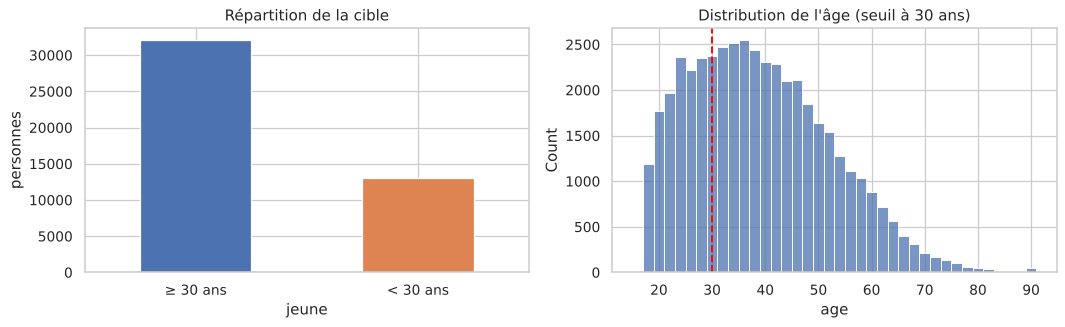

{'≥ 30 ans': 0.712, '< 30 ans': 0.288}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
data["jeune"].map({0: "≥ 30 ans", 1: "< 30 ans"}).value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Répartition de la cible"); ax[0].set_ylabel("personnes"); ax[0].tick_params(axis="x", rotation=0)
sns.histplot(df["age"], bins=range(15, 92, 2), ax=ax[1], color="#4C72B0")
ax[1].axvline(30, color="red", ls="--"); ax[1].set_title("Distribution de l'âge (seuil à 30 ans)")
plt.tight_layout(); plt.show()
print(y.value_counts(normalize=True).rename({0: "≥ 30 ans", 1: "< 30 ans"}).round(3).to_dict())

## 3.2 Quelles situations sont typiques des jeunes ?

Part de jeunes (< 30 ans) selon quelques variables. Une barre très au-dessus de la moyenne (ligne rouge) signale une situation « jeune ».

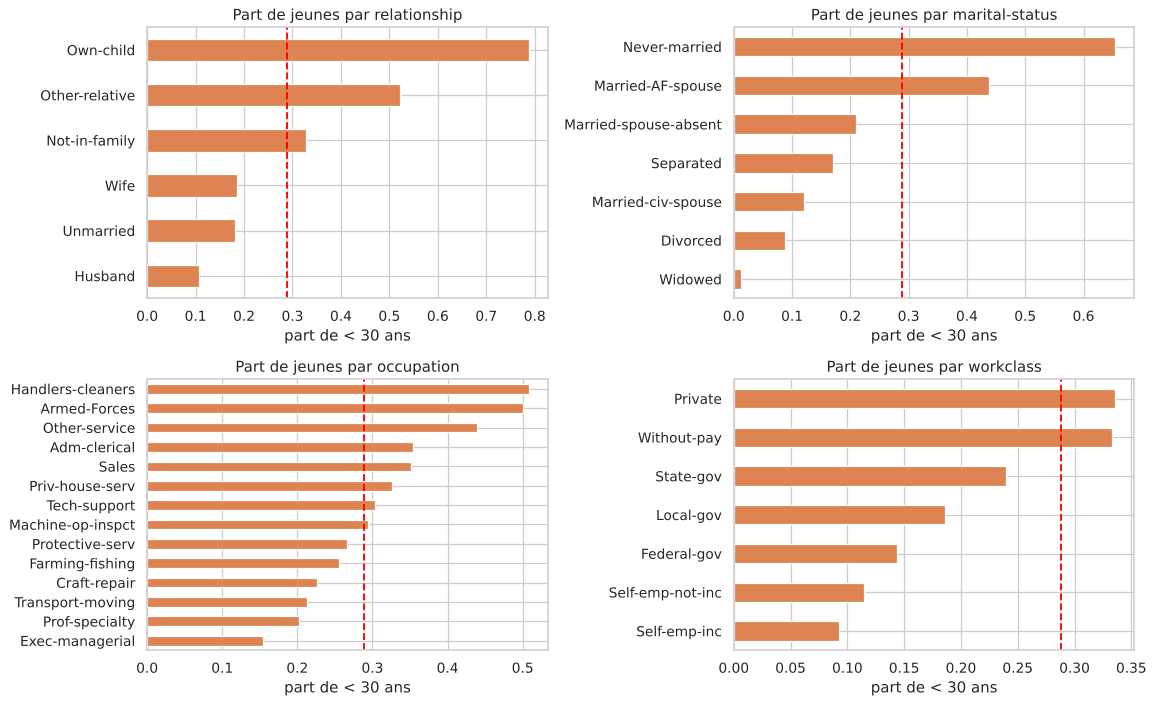

In [5]:
moy = y.mean()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["relationship", "marital-status", "occupation", "workclass"]):
    s = data.groupby(col)["jeune"].mean().sort_values()
    s.plot(kind="barh", ax=ax, color="#DD8452")
    ax.axvline(moy, color="red", ls="--"); ax.set_title(f"Part de jeunes par {col}"); ax.set_xlabel("part de < 30 ans"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [6]:
comp = data.groupby("jeune").agg(heures_moy=("hours-per-week", "mean"),
                                  part_temps_partiel=("hours-per-week", lambda h: (h < 35).mean()),
                                  part_revenu_gt50k=("income_gt50k", "mean"),
                                  annees_etudes=("education-num", "mean"))
comp.index = comp.index.map({0: "≥ 30 ans", 1: "< 30 ans"})
comp.round(3)

,heures_moy,part_temps_partiel,part_revenu_gt50k,annees_etudes
jeune,,,,
≥ 30 ans,42.597,0.104,0.326,10.273
< 30 ans,36.855,0.281,0.055,9.740


**Lecture.** Les jeunes travaillent moins d'heures, sont beaucoup plus souvent à temps partiel, et n'ont presque jamais un revenu > 50K. Les catégories `Own-child` (vit chez ses parents) et `Never-married` sont fortement « jeunes ». Ces écarts nets laissent prévoir un modèle bien meilleur que le hasard.

# 4. Baselines

Un modèle n'a de valeur que s'il **bat un prédicteur naïf**. On en teste deux :
- **Classe majoritaire** : répond toujours « pas jeune ».
- **Aléatoire stratifié** : tire au hasard en respectant les proportions.

On suit 4 métriques : **accuracy** (critère demandé), **balanced accuracy** (moyenne du rappel des deux classes, insensible au déséquilibre), **F1** sur la classe « jeune », et **ROC AUC** (qualité du classement, 0.5 = hasard).

In [7]:
def metrics(y_true, y_pred, y_proba=None):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "F1 (jeune)": f1_score(y_true, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_true, y_proba) if y_proba is not None else 0.5}

base = {}
for name, strat in [("Baseline majoritaire", "most_frequent"), ("Baseline aléatoire", "stratified")]:
    m = DummyClassifier(strategy=strat, random_state=RS).fit(X_train, y_train)
    base[name] = metrics(y_test, m.predict(X_test))
pd.DataFrame(base).T.round(3)

,accuracy,balanced_acc,F1 (jeune),ROC AUC
Baseline majoritaire,0.712,0.500,0.000,0.5
Baseline aléatoire,0.589,0.493,0.272,0.5


# 5. Comparaison des modèles (validation croisée 5-fold sur le train)

Quatre algorithmes de **classification** : voisins (KNN), arbre de décision, forêt aléatoire, gradient boosting. **Le test set n'est pas touché ici.**

In [8]:
models = {
    "KNN (k=25)":            KNeighborsClassifier(n_neighbors=25),
    "Arbre (depth=8)":       DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, random_state=RS),
    "Random Forest":         RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RS),
    "HistGradBoosting":      HistGradientBoostingClassifier(random_state=RS),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "F1 (jeune)": "f1", "ROC AUC": "roc_auc"}
rows = {}
for name, est in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", est)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {k: r[f"test_{k}"].mean() for k in scoring}
    rows[name]["accuracy std"] = r["test_accuracy"].std()
cv_res = pd.DataFrame(rows).T.sort_values("accuracy", ascending=False)
cv_res.round(3)

,accuracy,balanced_acc,F1 (jeune),ROC AUC,accuracy std
HistGradBoosting,0.832,0.778,0.690,0.873,0.004
Random Forest,0.831,0.772,0.683,0.871,0.004
Arbre (depth=8),0.829,0.778,0.689,0.865,0.006
KNN (k=25),0.828,0.771,0.681,0.856,0.004


# 6. Tuning du meilleur candidat (HistGradientBoosting)

Recherche aléatoire d'hyperparamètres, toujours en validation croisée sur le train, en optimisant l'**accuracy** (critère demandé).

In [9]:
pipe = Pipeline([("prep", preprocessor), ("model", HistGradientBoostingClassifier(random_state=RS))])
param_dist = {
    "model__learning_rate":     [0.03, 0.05, 0.1],
    "model__max_depth":         [3, 4, 6, None],
    "model__max_leaf_nodes":    [15, 31, 63],
    "model__min_samples_leaf":  [20, 50, 100],
    "model__l2_regularization": [0, 1, 10],
    "model__max_iter":          [200, 400],
}
search = RandomizedSearchCV(pipe, param_dist, n_iter=20, cv=cv, scoring="accuracy", n_jobs=-1, random_state=RS)
search.fit(X_train, y_train)
print("Meilleurs paramètres :", search.best_params_)
print("Accuracy CV : %.4f (défaut : %.4f)" % (search.best_score_, cv_res.loc["HistGradBoosting", "accuracy"]))
best_model = search.best_estimator_

Meilleurs paramètres : {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 31, 'model__max_iter': 200, 'model__max_depth': None, 'model__learning_rate': 0.1, 'model__l2_regularization': 10}
Accuracy CV : 0.8338 (défaut : 0.8323)


# 7. Évaluation finale sur le test set

Premier (et seul) passage sur le test set, avec le seuil standard de 0.5.

In [10]:
final = dict(base)
fitted = {}
for name, est in models.items():
    p = Pipeline([("prep", preprocessor), ("model", est)]).fit(X_train, y_train)
    fitted[name] = p
    final[name] = metrics(y_test, p.predict(X_test), p.predict_proba(X_test)[:, 1])
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
final["HistGB (tuné)"] = metrics(y_test, pred, proba)
res = pd.DataFrame(final).T.sort_values("accuracy", ascending=False)
res.round(3)

,accuracy,balanced_acc,F1 (jeune),ROC AUC
HistGB (tuné),0.834,0.776,0.689,0.874
HistGradBoosting,0.832,0.777,0.689,0.872
Random Forest,0.832,0.774,0.686,0.870
Arbre (depth=8),0.830,0.777,0.689,0.866
KNN (k=25),0.827,0.771,0.681,0.852
Baseline majoritaire,0.712,0.500,0.000,0.500
Baseline aléatoire,0.589,0.493,0.272,0.500


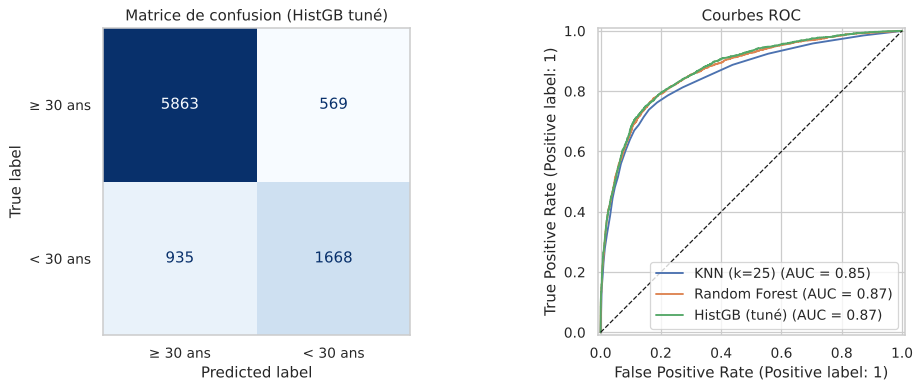

              precision    recall  f1-score   support

    ≥ 30 ans      0.862     0.912     0.886      6432
    < 30 ans      0.746     0.641     0.689      2603

    accuracy                          0.834      9035
   macro avg      0.804     0.776     0.788      9035
weighted avg      0.829     0.834     0.830      9035



In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["≥ 30 ans", "< 30 ans"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Matrice de confusion (HistGB tuné)"); ax[0].grid(False)
for name in ["KNN (k=25)", "Random Forest"]:
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, ax=ax[1], name=name)
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1], name="HistGB (tuné)")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("Courbes ROC")
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, target_names=["≥ 30 ans", "< 30 ans"], digits=3))

# 8. Seuil métier & bénéfices pour la banque

Le seuil 0.5 maximise l'accuracy, mais pour une **banque** les deux erreurs n'ont pas le même coût :
- **rater un jeune** = un client perdu, qui ira peut-être chez un concurrent pour des dizaines d'années ;
- **envoyer l'offre jeune à un client de 35 ans** = un SMS ou un e-mail perdu, qui coûte peu.

On veut donc surtout **ne pas rater de jeunes** (rappel élevé). On choisit donc le seuil qui maximise le **F1 de la classe « jeune »**, calculé sur des prédictions *out-of-fold* du **train** (pour ne pas tricher avec le test), puis on l'applique au test.

In [12]:
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.20, 0.71, 0.01), 2)
tab = pd.DataFrame([{"seuil": t,
                     "précision": precision_score(y_train, oof >= t),
                     "rappel": recall_score(y_train, oof >= t),
                     "F1": f1_score(y_train, oof >= t),
                     "accuracy": accuracy_score(y_train, oof >= t)} for t in grid]).set_index("seuil")
t_best = tab["F1"].idxmax()
print("Seuil retenu (max F1 sur le train) : %.2f" % t_best)
display(tab.loc[[0.20, 0.25, 0.30, t_best, 0.40, 0.45, 0.50, 0.60, 0.70]].sort_index().round(3))

cmp = pd.DataFrame({f"seuil 0.50": metrics(y_test, proba >= 0.5, proba),
                    f"seuil {t_best:.2f}": metrics(y_test, proba >= t_best, proba)}).T
cmp["précision"] = [precision_score(y_test, proba >= t) for t in [0.5, t_best]]
cmp["rappel"] = [recall_score(y_test, proba >= t) for t in [0.5, t_best]]
cmp.round(3)

Seuil retenu (max F1 sur le train) : 0.37


,précision,rappel,F1,accuracy
seuil,,,,
0.20,0.559,0.836,0.670,0.762
0.25,0.631,0.778,0.697,0.805
0.30,0.664,0.749,0.704,0.818
0.37,0.696,0.718,0.707,0.829
0.40,0.707,0.702,0.704,0.830
0.45,0.725,0.680,0.701,0.833
0.50,0.742,0.650,0.693,0.834
0.60,0.798,0.545,0.647,0.829
0.70,0.855,0.439,0.580,0.817


,accuracy,balanced_acc,F1 (jeune),ROC AUC,précision,rappel
seuil 0.50,0.834,0.776,0.689,0.874,0.746,0.641
seuil 0.37,0.830,0.796,0.709,0.874,0.700,0.717


## 8.1 Traduction en bénéfices concrets

On traduit les métriques en langage « banque », au seuil retenu :
- **Lift** = part de vrais jeunes parmi les clients ciblés par le modèle ÷ part de jeunes si on cible au hasard. Un lift de 2 veut dire « deux fois plus efficace qu'un envoi au hasard ».
- **Économie** = baisse du coût par jeune client touché (on paie chaque SMS / e-mail, mais seuls les jeunes nous intéressent).

In [13]:
def business(y_true, alert):
    prec, share = precision_score(y_true, alert), y_true.mean()
    return {"jeunes sur 1 000 clients ciblés (modèle)": round(prec * 1000),
            "jeunes sur 1 000 clients ciblés (hasard)": round(share * 1000),
            "lift (× plus efficace)": round(prec / share, 2),
            "économie par jeune touché": f"{(1 - share / prec) * 100:.0f} %",
            "part des jeunes retrouvés (rappel)": f"{recall_score(y_true, alert) * 100:.0f} %"}

pd.Series(business(y_test, proba >= t_best), name=f"modèle complet, seuil {t_best:.2f}").to_frame()

,"modèle complet, seuil 0.37"
jeunes sur 1 000 clients ciblés (modèle),700
jeunes sur 1 000 clients ciblés (hasard),288
lift (× plus efficace),2.43
économie par jeune touché,59 %
part des jeunes retrouvés (rappel),72 %


**Lecture.** Sur 1 000 clients choisis par le modèle, environ 7 sur 10 sont de vrais jeunes actifs, contre moins de 3 sur 10 en ciblant au hasard. Pour le même nombre de jeunes touchés, la campagne coûte donc **plus de deux fois moins cher**, et le modèle retrouve près de 3 jeunes sur 4.

# 9. Interprétation : quelles situations caractérisent les jeunes ?

Importance par permutation sur le test : on mélange une variable et on mesure la **baisse d'accuracy**. Si la brouiller ne change rien, elle ne sert pas au modèle.

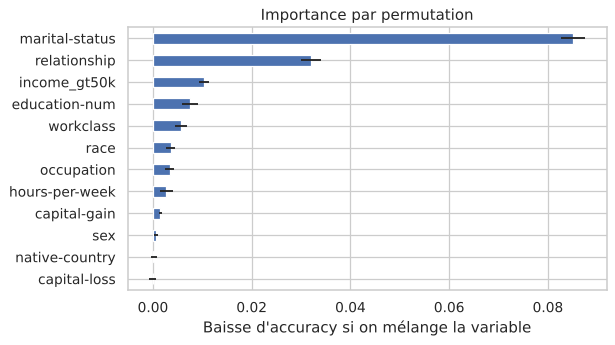

marital-status    0.0851
relationship      0.0321
income_gt50k      0.0104
education-num     0.0075
workclass         0.0056
race              0.0036
occupation        0.0034
hours-per-week    0.0027
capital-gain      0.0015
sex               0.0006
native-country    0.0003
capital-loss     -0.0001


In [14]:
pi = permutation_importance(best_model, X_test, y_test, scoring="accuracy", n_repeats=10, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot(kind="barh", xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index], ax=ax, color="#4C72B0")
ax.set_xlabel("Baisse d'accuracy si on mélange la variable"); ax.set_title("Importance par permutation")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4).to_string())

In [15]:
# Lecture métier : profils les plus / moins « jeunes »
g = data.groupby("occupation")["jeune"].agg(part_jeunes="mean", effectif="size").sort_values("part_jeunes", ascending=False)
g2 = data.groupby("relationship")["jeune"].agg(part_jeunes="mean", effectif="size").sort_values("part_jeunes", ascending=False)
display(g.round(3)); display(g2.round(3))

,part_jeunes,effectif
occupation,,
Handlers-cleaners,0.508,2045
Armed-Forces,0.500,14
Other-service,0.439,4805
Adm-clerical,0.354,5535
Sales,0.351,5405
Priv-house-serv,0.326,230
Tech-support,0.304,1419
Machine-op-inspct,0.293,2965
Protective-serv,0.267,975


,part_jeunes,effectif
relationship,,
Own-child,0.788,6616
Other-relative,0.522,1349
Not-in-family,0.328,11679
Wife,0.187,2091
Unmarried,0.181,4787
Husband,0.108,18653


# 10. Modèle du site : 7 variables, sans données sensibles

Pour le site web (démo commerciale), on simplifie le modèle :

| Variables retirées | Pourquoi |
|---|---|
| `sex`, `race`, `native-country` | **données sensibles** : une banque ne doit pas cibler selon le sexe ou l'origine (risque de discrimination) |
| `capital-gain`, `capital-loss` | données patrimoniales rarement connues, et quasi inutiles au modèle (partie 9) |

Il reste **7 informations simples** qu'un client peut donner en 30 secondes : profession, type d'employeur, heures par semaine, niveau d'études, revenu (> 50K ou non), situation familiale, logement / foyer. On garde **le même découpage train / test**, les **mêmes hyperparamètres** (partie 6) et la **même méthode de seuil** (partie 8). C'est exactement le modèle produit par `train_jeune.py` et utilisé par le site.

In [16]:
site_num = ["education-num", "hours-per-week", "income_gt50k"]
site_cat = ["workclass", "marital-status", "occupation", "relationship"]
site_features = site_num + site_cat
assert "age" not in site_features

site_model = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), site_num),
                                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), site_cat)])),
    ("model", HistGradientBoostingClassifier(random_state=RS)),
]).set_params(**search.best_params_)

Xs_train, Xs_test = X_train[site_features], X_test[site_features]
oof_site = cross_val_predict(site_model, Xs_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
t_site = float(grid[np.argmax([f1_score(y_train, oof_site >= t) for t in grid])])

site_model.fit(Xs_train, y_train)
proba_site = site_model.predict_proba(Xs_test)[:, 1]

r3 = lambda d: {k: round(v, 3) for k, v in d.items()}
cmp_site = pd.DataFrame({
    f"Complet (12 var.), seuil {t_best:.2f}": {**r3(metrics(y_test, proba >= t_best, proba)), **business(y_test, proba >= t_best)},
    f"Site (7 var.), seuil {t_site:.2f}":     {**r3(metrics(y_test, proba_site >= t_site, proba_site)), **business(y_test, proba_site >= t_site)},
})
print("Accuracy au seuil 0.5 : complet %.3f | site %.3f" % (accuracy_score(y_test, proba >= .5), accuracy_score(y_test, proba_site >= .5)))
cmp_site

Accuracy au seuil 0.5 : complet 0.834 | site 0.831


,"Complet (12 var.), seuil 0.37","Site (7 var.), seuil 0.36"
accuracy,0.83,0.829
balanced_acc,0.796,0.798
F1 (jeune),0.709,0.71
ROC AUC,0.874,0.873
jeunes sur 1 000 clients ciblés (modèle),700,693
jeunes sur 1 000 clients ciblés (hasard),288,288
lift (× plus efficace),2.43,2.41
économie par jeune touché,59 %,58 %
part des jeunes retrouvés (rappel),72 %,73 %


**Lecture.** Retirer le sexe, l'origine, le pays et les données de capital ne coûte **presque rien** (quelques dixièmes de point d'accuracy, même lift d'environ 2,4×). Le modèle simplifié est donc meilleur pour un vrai client : **plus éthique, plus rapide à remplir, et aussi efficace**. C'est lui qui est déployé sur le site.

# 11. Conclusion

**Performance.** Le meilleur modèle (HistGradientBoosting tuné) atteint sur le test une **accuracy de 83,4 %**, largement au-dessus du seuil demandé (60 %) et surtout **au-dessus de la baseline majoritaire (71,2 %)** : +12 points. La **balanced accuracy (77,6 %)** et le **ROC AUC (0,87)** confirment que le modèle a réellement appris à distinguer les deux classes, et ne profite pas seulement du déséquilibre.

**Comparaison des modèles.** Les quatre classifieurs obtiennent des scores très proches (accuracy 82,7 – 83,4 %, AUC 0,852 – 0,874) et le tuning n'apporte que +0,1 point. Le signal est donc **fort et simple** : même un **arbre de décision** de profondeur 8 (83,0 %), facile à expliquer, est une alternative défendable au boosting.

**Ce que la banque ou l'assureur y gagne.** Au seuil métier (choisi sur le train pour ne pas rater de jeunes) :
- **Cibler les bons clients** : sur 1 000 clients choisis par le modèle, environ **700 sont de vrais jeunes actifs**, contre **288** en ciblant au hasard → **2,4 fois plus efficace**.
- **Dépenser moins** : pour le même nombre de jeunes touchés, le coût marketing par jeune baisse d'environ **58 %**.
- **Fidéliser tôt** : le modèle retrouve **près de 3 jeunes sur 4** (rappel 72 – 73 %), à un âge où le client choisit sa banque et son assureur pour longtemps.

**Modèle déployé sur le site.** Sans le sexe, l'origine, le pays ni les données de capital, le modèle à **7 variables** garde pratiquement les mêmes performances (accuracy 82,9 % au seuil métier, 83,1 % au seuil 0,5, AUC 0,873, lift 2,4×). Il est **plus éthique, plus simple à remplir et aussi efficace** : c'est lui qu'utilise le site (`train_jeune.py`, page `/jeune-actif/`).

**Ce qui caractérise un jeune actif.** La situation familiale domine : **célibataire** (65 % de jeunes) et **vit chez ses parents** (79 % de jeunes). Viennent ensuite le revenu (seulement 5,5 % des jeunes dépassent 50K, contre 32,6 % des plus âgés), le niveau d'études et le type d'employeur. Les jeunes sont surtout dans le **privé**, dans les métiers de **manutention, services, vente et administratif**, et sont **2,7 fois plus souvent à temps partiel**. Ces constats aident aussi à concevoir les offres : petits budgets, premier logement, besoin d'une banque simple et mobile.

**Limites et usage responsable.**
- Données du recensement américain de **1994** : à ré-entraîner sur les données réelles du client (banque tunisienne, par exemple) avant tout usage.
- L'âge est un **critère protégé** : le modèle sert **uniquement à choisir quelle offre marketing montrer**, jamais à refuser un crédit, un contrat ou à fixer un prix.
- Le modèle décrit des **parcours de vie** (études, vie chez les parents, mariage plus tardif) : il peut se tromper sur des profils atypiques, d'où l'intérêt d'afficher une **probabilité** et un niveau de confiance plutôt qu'un simple oui / non.

**Pistes.** Ré-entraîner sur des données clients récentes ; tester 3 segments (< 30 / 30 – 50 / 50 +) pour proposer aussi des offres **seniors** (retraite, santé) ; mesurer le vrai gain par un **test A/B** sur une campagne réelle.
